# Data Ingestion & Cleaning

In [19]:
import pandas as pd
import numpy as np
import os
import warnings
warnings.filterwarnings('ignore')

print("=== 1. VERİ SETLERİ YÜKLENİYOR VE HAZIRLANIYOR ===")

=== 1. VERİ SETLERİ YÜKLENİYOR VE HAZIRLANIYOR ===


In [20]:
# Dosya yollarını kontrol eden yardımcı fonksiyon
def get_file_path(filename):
    if os.path.exists(f"data/{filename}"):
        return f"data/{filename}"
    elif os.path.exists(filename):
        return filename
    else:
        raise FileNotFoundError(f"⚠️ Dosya bulunamadı: {filename}. Lütfen 'data/' klasörüne koyduğunuzdan emin olun.")


In [21]:
# 1. Tarihsel Özet Verisi (1988 - 2024)
file_yearly = get_file_path('Orman yangınları, 1988-2024.csv')
df_yearly = pd.read_csv(file_yearly, sep=';', encoding='windows-1254')

In [22]:
# Sayısal veri temizliği (nokta ve tire temizleme)
for col in df_yearly.columns:
    if col != 'Yıl':
        df_yearly[col] = df_yearly[col].astype(str).str.replace('.', '', regex=False).str.replace('-', '0').str.replace(',', '.', regex=False)
        df_yearly[col] = pd.to_numeric(df_yearly[col], errors='coerce').fillna(0)

print(f"✅ 1. Tarihsel Veri Yüklendi (1988-2024): {len(df_yearly)} Yıllık Kayıt")

✅ 1. Tarihsel Veri Yüklendi (1988-2024): 37 Yıllık Kayıt


In [23]:
# 2. 2024 İller Dağılımı Verisi
file_illere = get_file_path('2.14 İllere göre orman yangınlarının dağılımı,2024.csv')
df_illere = pd.read_csv(file_illere, sep=';', encoding='windows-1254').dropna(subset=['İller'])

df_illere['Adet'] = pd.to_numeric(df_illere['Adet'].astype(str).str.replace('.', '', regex=False).str.replace(',', '.', regex=False), errors='coerce')
df_illere['Hektar'] = pd.to_numeric(df_illere['Hektar'].astype(str).str.replace('.', '', regex=False).str.replace(',', '.', regex=False), errors='coerce')
df_illere = df_illere[df_illere['İl_kodu'] != 'TR'] # Türkiye genel satırını ayırıyoruz

print(f"✅ 2. İller Bazlı 2024 Verisi Yüklendi: {len(df_illere)} Şehir")

✅ 2. İller Bazlı 2024 Verisi Yüklendi: 81 Şehir


In [24]:
# 3. 2024 Yangın Çıkış Sebepleri (Bölge Müdürlükleri)
file_causes = get_file_path('2_15_Yangınların_çıkış_sebeplerinin_bölge_müdürlüklerine_alansal.csv')
df_causes = pd.read_csv(file_causes, sep=';', encoding='windows-1254')

num_cols = [c for c in df_causes.columns if c != 'Orman Bölge Müdürlüğü']
for c in num_cols:
    df_causes[c] = pd.to_numeric(df_causes[c].astype(str).str.replace('-', '0').str.replace('.', '', regex=False).str.replace(',', '.', regex=False), errors='coerce').fillna(0)

print(f"✅ 3. Çıkış Sebepleri Verisi Yüklendi: {len(df_causes)} Bölge Müdürlüğü")

✅ 3. Çıkış Sebepleri Verisi Yüklendi: 32 Bölge Müdürlüğü


In [25]:
# 4. Global Forest Watch (GFW) Türkiye Ağaç Örtüsü Kaybı Verisi
file_gfw = get_file_path('treecover_loss_from_fires_by_region__ha.csv')
df_gfw = pd.read_csv(file_gfw, sep=';', encoding='windows-1254')
df_gfw_tur = df_gfw[df_gfw['iso'] == 'TUR'].copy()

print(f"✅ 4. Global Forest Watch Verisi Yüklendi: {len(df_gfw_tur)} Yıllık Global Yangın Kaydı")

print("\n🎉 TÜM VERİ SETLERİ BAŞARIYLA BELLEĞE ALINDI VE TEMİZLENDİ!")

✅ 4. Global Forest Watch Verisi Yüklendi: 24 Yıllık Global Yangın Kaydı

🎉 TÜM VERİ SETLERİ BAŞARIYLA BELLEĞE ALINDI VE TEMİZLENDİ!


# Exploratory Data Analysis (EDA) & Biodiversity Metrics


=== 2. KEŞİFÇİ VERİ ANALİZİ (EDA) & BÖLGESEL BİYOÇEŞİTLİLİK RİSKİ ===


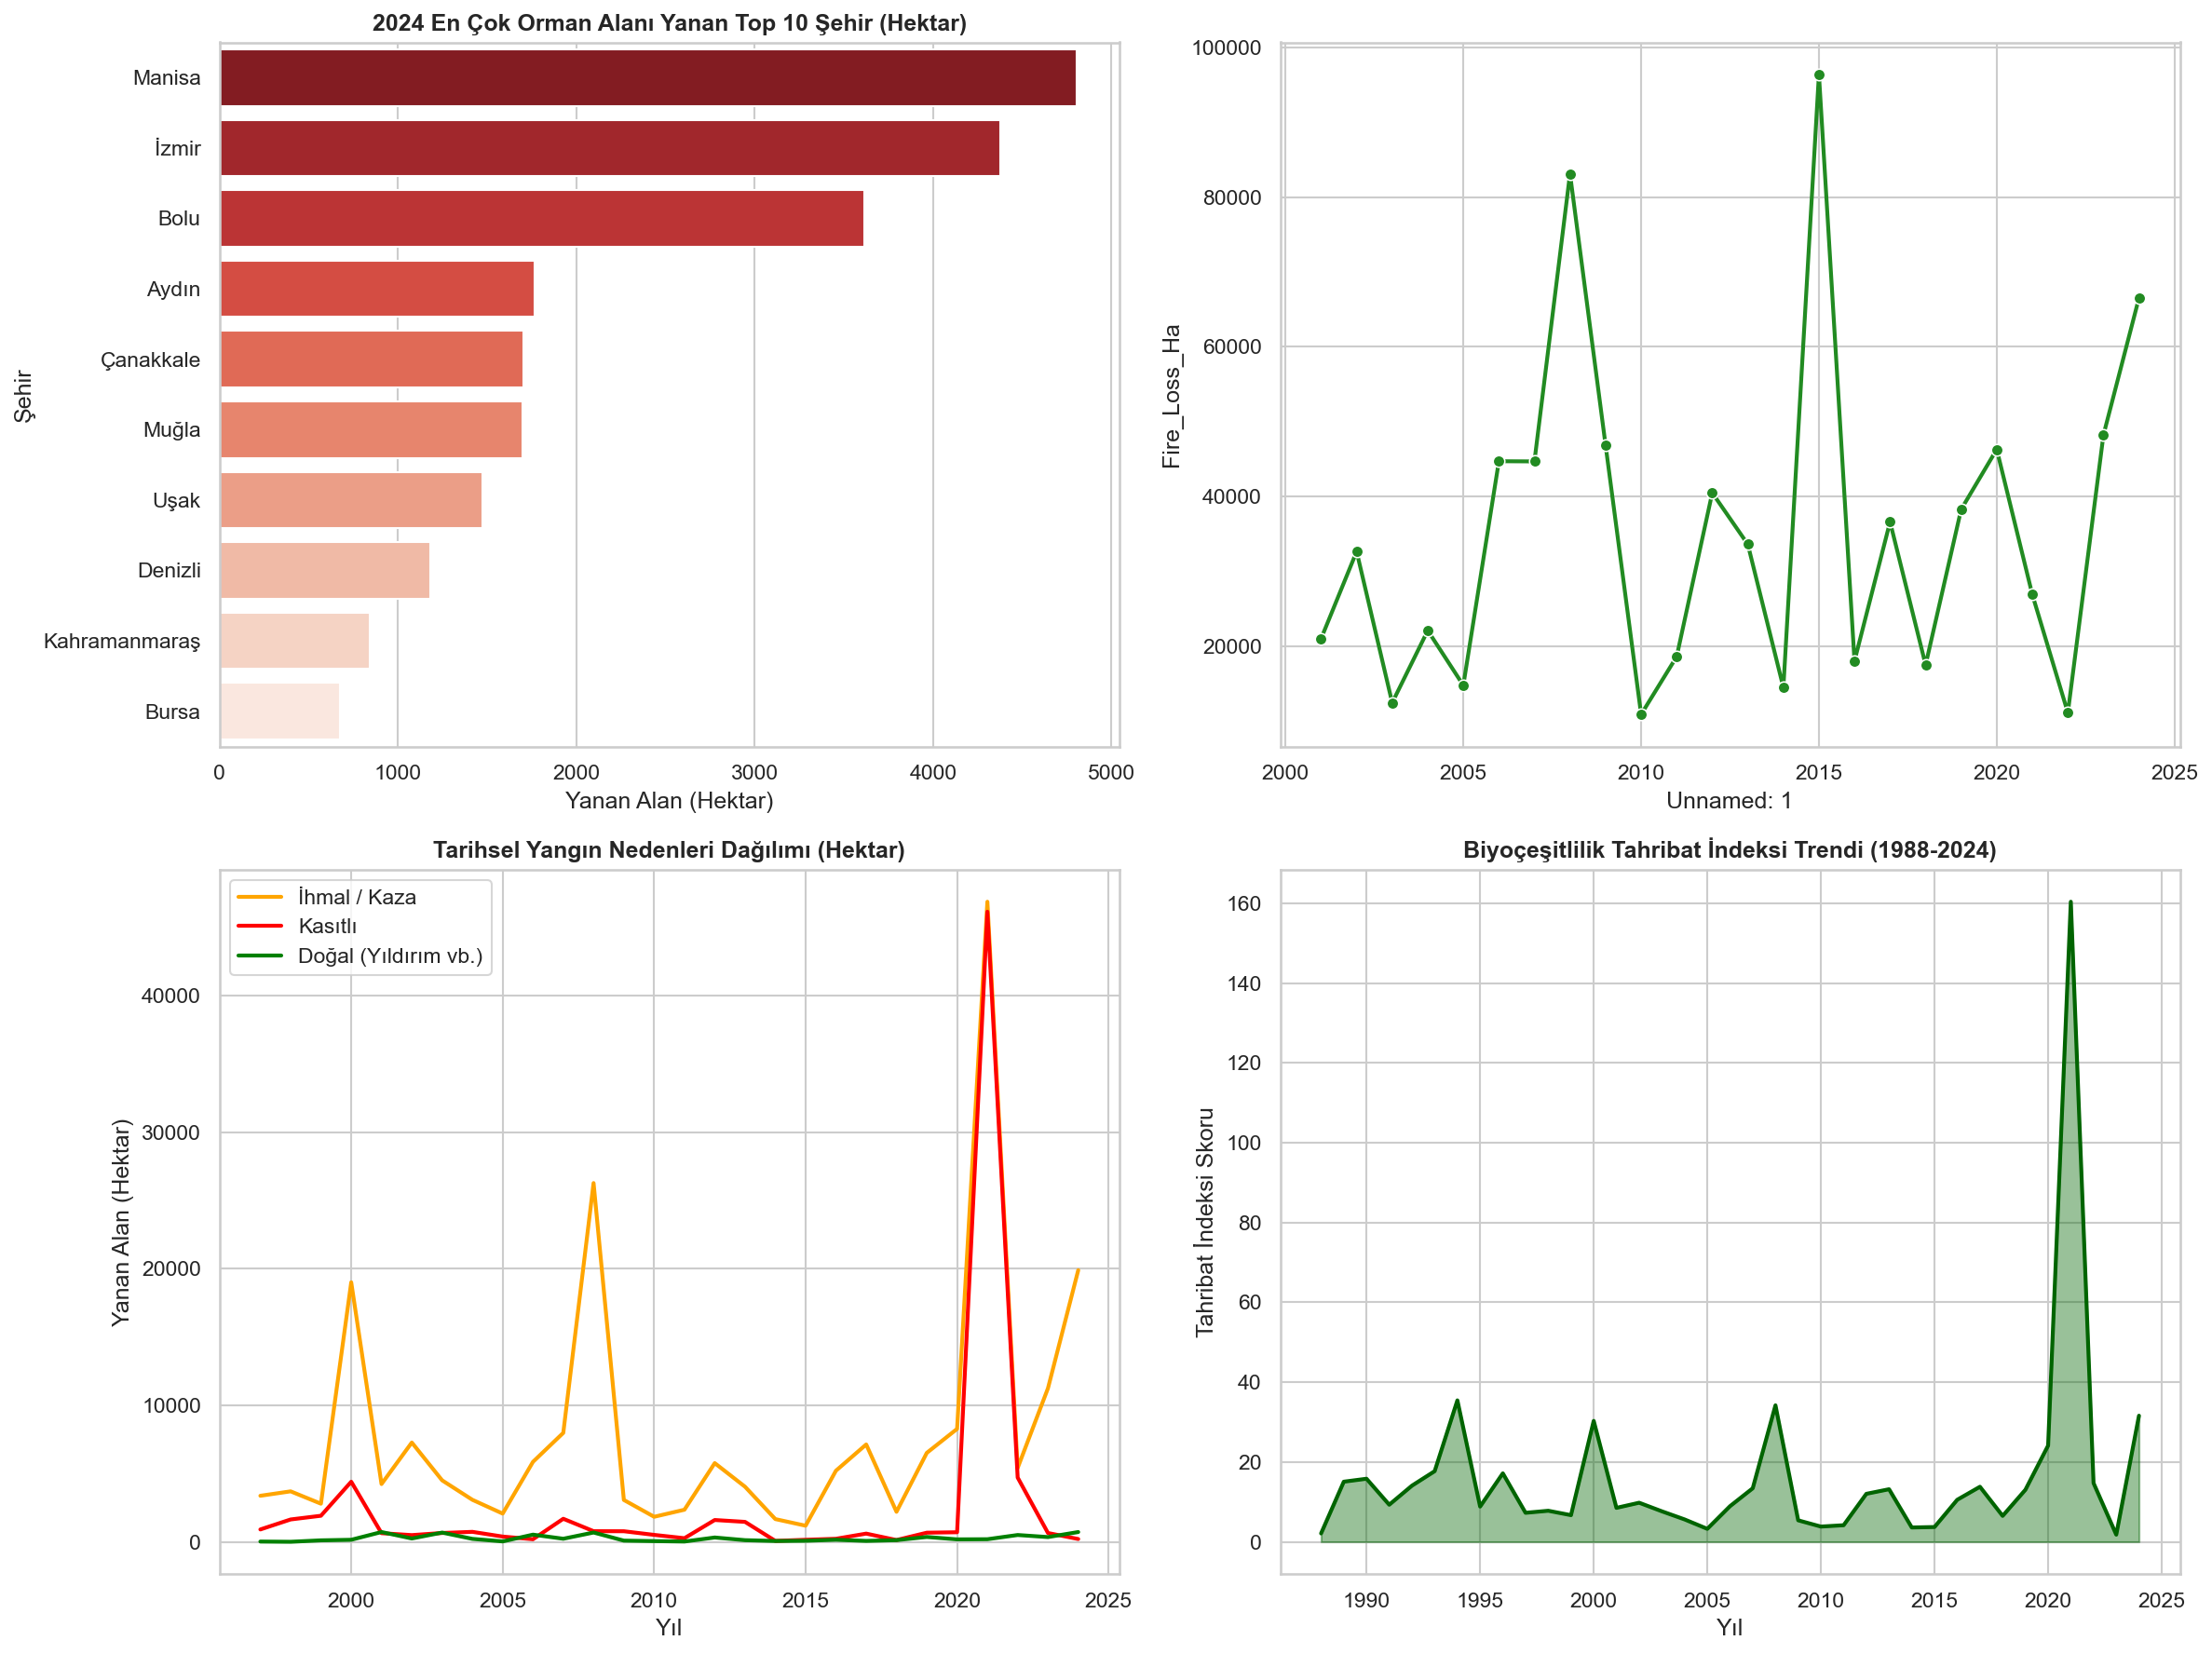

✅ EDA ve Bölgesel Biyoçeşitlilik Analizi Tamamlandı! Dashboard 'assets/eda_biodiversity_risk_dashboard.png' olarak kaydedildi.


In [35]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import os

# Görselleştirme Teması
sns.set_theme(style="whitegrid")
plt.rcParams['figure.dpi'] = 150

print("=== 2. KEŞİFÇİ VERİ ANALİZİ (EDA) & BÖLGESEL BİYOÇEŞİTLİLİK RİSKİ ===")

# 4'lü Grafik Paneli Başlatma
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# -------------------------------------------------------------
# Grafik 1: 2024 En Çok Yanan Top 10 Şehir (Hektar)
# -------------------------------------------------------------
top10_illere = df_illere.sort_values(by='Hektar', ascending=False).head(10)
sns.barplot(ax=axes[0, 0], data=top10_illere, x='Hektar', y='İller', palette='Reds_r')
axes[0, 0].set_title('2024 En Çok Orman Alanı Yanan Top 10 Şehir (Hektar)', fontsize=12, fontweight='bold')
axes[0, 0].set_xlabel('Yanan Alan (Hektar)')
axes[0, 0].set_ylabel('Şehir')

# -------------------------------------------------------------
# Grafik 2: Global Forest Watch - Türkiye Ağaç Örtüsü Kaybı Trendi
# -------------------------------------------------------------
# Grafik 2: GFW Verisi (Dinamik İndeks ile Kolon Yakalama)
x_year_col = df_gfw_tur.columns[1]  # 2. Kolon: Yıl kolonu
y_fire_col = df_gfw_tur.columns[3]  # 4. Kolon: Yangın kaynaklı kayıp kolonu

df_gfw_tur['Fire_Loss_Ha'] = pd.to_numeric(
    df_gfw_tur[y_fire_col].astype(str).str.replace('.', '', regex=False).str.slice(0, 5), 
    errors='coerce'
)
sns.lineplot(ax=axes[0, 1], data=df_gfw_tur, x=x_year_col, y='Fire_Loss_Ha', marker='o', color='forestgreen', linewidth=2)

# -------------------------------------------------------------
# Grafik 3: Tarihsel Yangın Çıkış Sebepleri (1997-2024)
# -------------------------------------------------------------
df_history_causes = df_yearly[df_yearly['Yıl'] >= 1997]
axes[1, 0].plot(df_history_causes['Yıl'], df_history_causes['İhmal_hektar'], label='İhmal / Kaza', color='orange', linewidth=2)
axes[1, 0].plot(df_history_causes['Yıl'], df_history_causes['Kasıtlı_hektar'], label='Kasıtlı', color='red', linewidth=2)
axes[1, 0].plot(df_history_causes['Yıl'], df_history_causes['Dogal_hektar'], label='Doğal (Yıldırım vb.)', color='green', linewidth=2)
axes[1, 0].set_title('Tarihsel Yangın Nedenleri Dağılımı (Hektar)', fontsize=12, fontweight='bold')
axes[1, 0].set_xlabel('Yıl')
axes[1, 0].set_ylabel('Yanan Alan (Hektar)')
axes[1, 0].legend()

# -------------------------------------------------------------
# Grafik 4: Biyoçeşitlilik Tahribat İndeksi (1988-2024)
# -------------------------------------------------------------
df_yearly['Biodiversity_Damage_Index'] = (df_yearly['Yanan_alan_ha'] * 1.15) / 1000
axes[1, 1].fill_between(df_yearly['Yıl'], df_yearly['Biodiversity_Damage_Index'], color='darkgreen', alpha=0.4)
axes[1, 1].plot(df_yearly['Yıl'], df_yearly['Biodiversity_Damage_Index'], color='darkgreen', linewidth=2)
axes[1, 1].set_title('Biyoçeşitlilik Tahribat İndeksi Trendi (1988-2024)', fontsize=12, fontweight='bold')
axes[1, 1].set_xlabel('Yıl')
axes[1, 1].set_ylabel('Tahribat İndeksi Skoru')

plt.tight_layout()

# Görseli Kaydetme ve Ekrana Basma
os.makedirs('assets', exist_ok=True)
plt.savefig('assets/eda_biodiversity_risk_dashboard.png', dpi=300)
plt.show()

print("✅ EDA ve Bölgesel Biyoçeşitlilik Analizi Tamamlandı! Dashboard 'assets/eda_biodiversity_risk_dashboard.png' olarak kaydedildi.")

=== 3. MACHINE LEARNING & 2030 RİSK PROJEKSİYONU ===
📈 2030 Tahmini İhmal Kaynaklı Yanan Alan: 14,416 Hektar
📈 2030 Tahmini Kasıtlı Yanan Alan: 7,350 Hektar


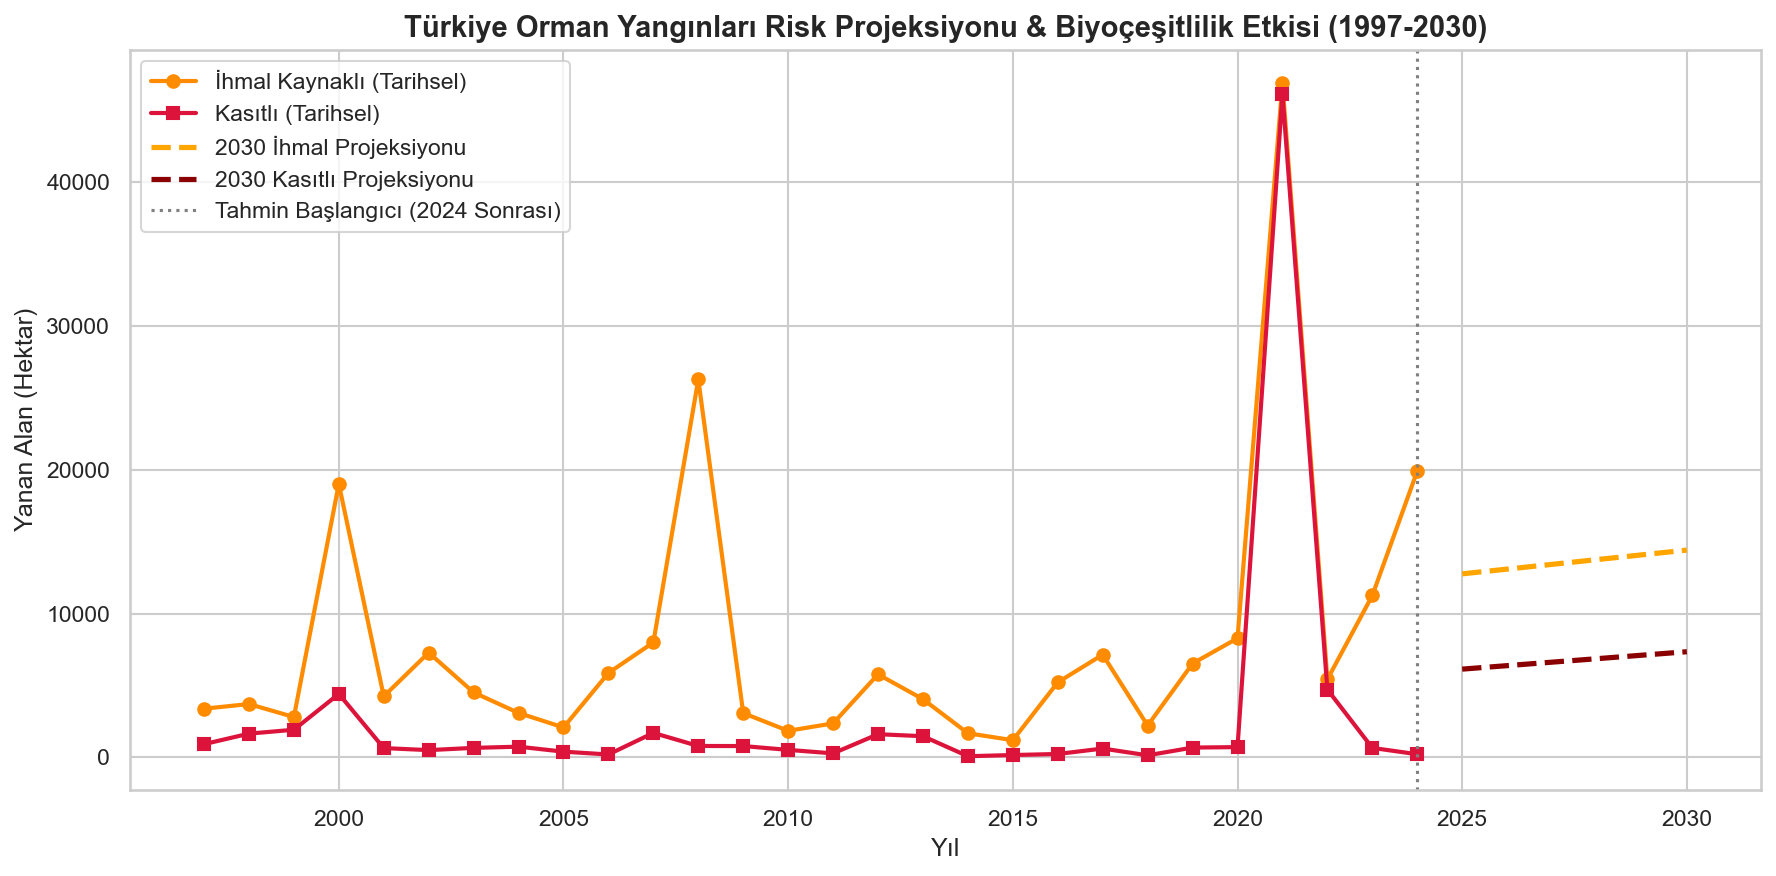


✅ Grafiğin 'assets/2030_wildfire_biodiversity_projection.png' konumuna kaydedildi!


In [36]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression
import pandas as pd
import os

print("=== 3. MACHINE LEARNING & 2030 RİSK PROJEKSİYONU ===")

# 1997 Sonrası Verileri Modelleme (Çünkü neden verileri 1997'de başlıyor)
df_ml = df_yearly[df_yearly['Yıl'] >= 1997].copy()

X = df_ml[['Yıl']]
y_negligence = df_ml['İhmal_hektar']
y_intentional = df_ml['Kasıtlı_hektar']

# Scikit-Learn Linear Regression Modelleri
model_neg = LinearRegression().fit(X, y_negligence)
model_int = LinearRegression().fit(X, y_intentional)

# 2025-2030 Gelecek Yıllar Tahmini
future_years = pd.DataFrame({'Yıl': list(range(2025, 2031))})
future_years['Pred_İhmal'] = model_neg.predict(future_years[['Yıl']])
future_years['Pred_Kasıtlı'] = model_int.predict(future_years[['Yıl']])

pred_2030_neg = future_years[future_years['Yıl'] == 2030]['Pred_İhmal'].values[0]
pred_2030_int = future_years[future_years['Yıl'] == 2030]['Pred_Kasıtlı'].values[0]

print(f"📈 2030 Tahmini İhmal Kaynaklı Yanan Alan: {pred_2030_neg:,.0f} Hektar")
print(f"📈 2030 Tahmini Kasıtlı Yanan Alan: {pred_2030_int:,.0f} Hektar")

# Tahmin Grafiğini Çizdirme
plt.figure(figsize=(12, 6))

plt.plot(df_ml['Yıl'], df_ml['İhmal_hektar'], label='İhmal Kaynaklı (Tarihsel)', color='darkorange', linewidth=2, marker='o')
plt.plot(df_ml['Yıl'], df_ml['Kasıtlı_hektar'], label='Kasıtlı (Tarihsel)', color='crimson', linewidth=2, marker='s')

plt.plot(future_years['Yıl'], future_years['Pred_İhmal'], '--', label='2030 İhmal Projeksiyonu', color='orange', linewidth=2.5)
plt.plot(future_years['Yıl'], future_years['Pred_Kasıtlı'], '--', label='2030 Kasıtlı Projeksiyonu', color='darkred', linewidth=2.5)

plt.axvline(x=2024, color='gray', linestyle=':', label='Tahmin Başlangıcı (2024 Sonrası)')

plt.title('Türkiye Orman Yangınları Risk Projeksiyonu & Biyoçeşitlilik Etkisi (1997-2030)', fontsize=14, fontweight='bold')
plt.xlabel('Yıl')
plt.ylabel('Yanan Alan (Hektar)')
plt.legend()
plt.tight_layout()

# assets klasörünü oluşturup grafiği kaydetme
os.makedirs('assets', exist_ok=True)
plt.savefig('assets/2030_wildfire_biodiversity_projection.png', dpi=300)
plt.show()

print("\n✅ Grafiğin 'assets/2030_wildfire_biodiversity_projection.png' konumuna kaydedildi!")